What is the most optimal skill to learn for Data Analysts?

Methodology     

1.Group skills to determine median salary and likelihood of being in posting
2.Visualize median salary vs percent skill demand 
3.(Optional) determine if certain technologies are more prevalent.

In [2]:

import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

df = pd.read_csv('indian_tech_jobs_2026.csv')

df['scraped_at'] = pd.to_datetime(df['scraped_at'])

df['skills_required'] = (
    df['skills_required']
    .fillna('')
    .replace('Not Available', '')
    .str.split(', ')
)

In [3]:
df_IND = df[(df['job_title'] == 'Data Analyst')].copy()

In [4]:
df['salary_year_avg'] = (df['salary_min_lpa'] + df['salary_max_lpa']) / 2

In [5]:
df_IND = df_IND.dropna(subset=['salary_midpoint_lpa']).copy()

if isinstance(df_IND['skills_required'].iloc[0], str):
    df_IND['skills_required'] = df_IND['skills_required'].str.split(', ')

df_IND_exploded = df_IND.explode('skills_required')

df_IND_exploded[['salary_midpoint_lpa', 'skills_required']].head(5)

,salary_midpoint_lpa,skills_required
657,6.5,Data Analytics
657,6.5,Power Bi
657,6.5,Statistics
657,6.5,Python
657,6.5,SQL


In [6]:
df_IND_skills = df_IND_exploded.groupby('skills_required')['salary_midpoint_lpa'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_IND_skills = df_IND_skills.rename(columns={'count': 'skill_count', 'median': 'median_salary'})

df_job_count = len(df_IND)

skill_percent = 5

df_IND_skills['skill_percent'] = df_IND_skills['skill_count'] / df_job_count * 100

df_IND_skills_high_demand = df_IND_skills[df_IND_skills['skill_percent'] > skill_percent]

df_IND_skills_high_demand


,skill_count,median_salary,skill_percent
skills_required,,,
Data analysis,164,0.000,40.594059
Data Analyst,134,0.000,33.168317
SQL,105,0.000,25.990099
Data,96,0.000,23.762376
Analytical,77,0.000,19.059406
Power Bi,67,0.600,16.584158
Analytics,64,0.000,15.841584
data analysis,56,0.000,13.861386
power bi,52,0.000,12.871287


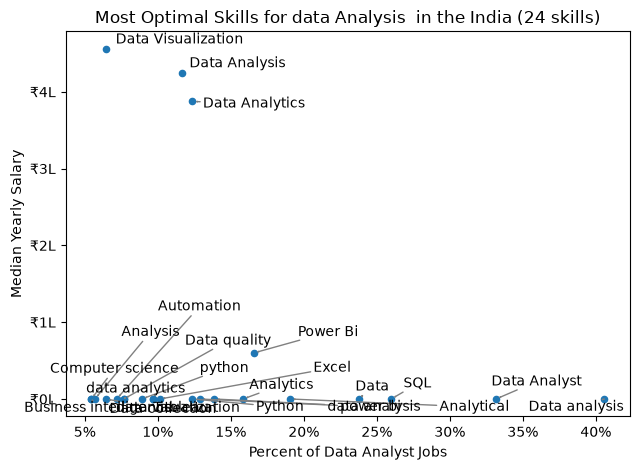

In [7]:
from adjustText import adjust_text

texts = []
df_IND_skills_high_demand.plot(kind='scatter', x='skill_percent', y='median_salary')

for i, txt in enumerate(df_IND_skills_high_demand.index):
    texts.append(plt.text(df_IND_skills_high_demand['skill_percent'].iloc[i], df_IND_skills_high_demand['median_salary'].iloc[i], txt))

adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary')
plt.title(f'Most Optimal Skills for data Analysis  in the India ({df_IND_skills_high_demand.shape[0]} skills)')
plt.tight_layout()

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'₹{int(y)}L'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

plt.show()

In [8]:
df['skills_required'].head(10)

0    [Computer science, Data analysis, data science...
1    [Basic, Data management, Business analytics, A...
2                                                   []
3                                                   []
4                                                   []
5                                                   []
6                                                   []
7    [Supply chain, data science, Aerospace, Machin...
8    [Product management, Prototype, data science, ...
9    [python, data analysis, data domain, vertex, d...
Name: skills_required, dtype: object

In [ ]:
import ast
import pandas as pd

def parse_skills(val):
    if isinstance(val, list):
        return val
    if isinstance(val, str):
        val = val.strip()
        if val.startswith('[') and val.endswith(']'):
            try:
                return ast.literal_eval(val)
            except (ValueError, SyntaxError):
                pass
        return [s.strip() for s in val.split(',') if s.strip()]
    return []

df_clean = df[df['skills_required'].notna() & (df['skills_required'] != 'Not Available')].copy()
df_clean['skills_list'] = df_clean['skills_required'].apply(parse_skills)

df_exploded = df_clean.explode('skills_list')
df_exploded['skill'] = df_exploded['skills_list'].astype(str).str.strip().str.title()

category_map = {
    'Programming': ['Python', 'R', 'Scala', 'Java', 'C++', 'Vba', 'Sas', 'Matlab'],
    'Databases': ['Sql', 'Postgresql', 'Mysql', 'Oracle', 'Mongodb', 'Nosql', 'Sql Server', 'Sqlite'],
    'Bi & Visualization': ['Power Bi', 'Tableau', 'Excel', 'Looker', 'Plotly', 'Matplotlib', 'Seaborn', 'Qlik'],
    'Cloud & Big Data': ['Aws', 'Azure', 'Azure Cloud', 'Gcp', 'Snowflake', 'Databricks', 'Data Bricks', 'Pyspark', 'Spark', 'Hadoop', 'Bigquery'],
    'Data Science & Ml': ['Machine Learning', 'Deep Learning', 'Pandas', 'Numpy', 'Scikit-Learn', 'Tensorflow', 'Pytorch', 'Nlp', 'Eda', 'Statistics']
}

skill_to_cat = {skill: cat for cat, skills in category_map.items() for skill in skills}

df_exploded['technology'] = df_exploded['skill'].map(skill_to_cat)

tech_dict = (
    df_exploded.dropna(subset=['technology'])
    .groupby('technology')['skill']
    .unique()
    .apply(list)
    .to_dict()
)

for category, tools in tech_dict.items():
    print(f"[{category}]: {tools}")

[Bi & Visualization]: ['Power Bi', 'Matplotlib', 'Excel', 'Tableau', 'Plotly', 'Looker', 'Qlik']
[Cloud & Big Data]: ['Gcp', 'Azure', 'Aws', 'Hadoop', 'Snowflake', 'Bigquery', 'Data Bricks', 'Pyspark', 'Spark', 'Databricks', 'Azure Cloud']
[Data Science & Ml]: ['Machine Learning', 'Statistics', 'Scikit-Learn', 'Tensorflow', 'Numpy', 'Deep Learning', 'Pytorch', 'Pandas', 'Nlp', 'Eda']
[Databases]: ['Sql', 'Sql Server', 'Mysql', 'Oracle', 'Postgresql', 'Mongodb', 'Nosql', 'Sqlite']
[Programming]: ['Python', 'Matlab', 'Sas', 'R', 'Scala', 'C++', 'Java', 'Vba']


In [59]:
df_tech = pd.DataFrame(list(tech_dict.items()), columns=['technology', 'skills'])
df_tech_exploded = df_tech.explode('skills')



In [55]:
import ast
import pandas as pd

# 1. Helper function to safely parse stringified lists or comma-separated strings
def parse_skills(val):
    if isinstance(val, list):
        return val
    if isinstance(val, str):
        val = val.strip()
        if val.startswith('[') and val.endswith(']'):
            try:
                return ast.literal_eval(val)
            except (ValueError, SyntaxError):
                pass
        return [s.strip() for s in val.split(',') if s.strip()]
    return []

# 2. Filter for Data Analyst postings and create df_da_clean
df_da = df[df['job_title'] == 'Data Analyst'].copy()
total_da_jobs = len(df_da)

df_da = df_da[df_da['skills_required'].notna() & (df_da['skills_required'] != 'Not Available')].copy()
df_da['skills_list'] = df_da['skills_required'].apply(parse_skills)

df_da_clean = df_da.explode('skills_list').copy()
df_da_clean['skill'] = df_da_clean['skills_list'].astype(str).str.strip().str.title()

# 3. Calculate demand % from ALL Data Analyst postings
demand_df = (
    df_da_clean.groupby('skill')
    .size()
    .reset_index(name='skill_count')
)
demand_df['skill_percent'] = (demand_df['skill_count'] / total_da_jobs) * 100

# 4. Calculate median salary ONLY from postings with disclosed salaries (> 0)
salary_df = (
    df_da_clean[df_da_clean['salary_midpoint_lpa'] > 0]
    .groupby('skill')['salary_midpoint_lpa']
    .median()
    .reset_index(name='median_salary')
)

# 5. Combine demand + valid salary, deduplicate lookup table, and merge
df_combined = demand_df.merge(salary_df, on='skill', how='inner')
df_tech_unique = df_tech_exploded.drop_duplicates(subset=['skills'])

df_plot = (
    df_combined.merge(df_tech_unique, left_on='skill', right_on='skills', how='inner')
    .sort_values(by='skill_count', ascending=False)
    .head(10)
)

df_plot

,skill,skill_count,skill_percent,median_salary,technology,skills
12,Power Bi,121,29.950495,6.25,Bi & Visualization,Power Bi
17,Sql,112,27.722772,6.50,Databases,Sql
13,Python,86,21.287129,6.50,Programming,Python
19,Tableau,53,13.118812,6.50,Bi & Visualization,Tableau
4,Excel,49,12.128713,6.00,Bi & Visualization,Excel
7,Machine Learning,37,9.158416,6.00,Data Science & Ml,Machine Learning
18,Statistics,13,3.217822,5.12,Data Science & Ml,Statistics
11,Postgresql,9,2.227723,28.75,Databases,Postgresql
15,Snowflake,9,2.227723,17.50,Cloud & Big Data,Snowflake
1,Data Bricks,8,1.980198,17.50,Cloud & Big Data,Data Bricks


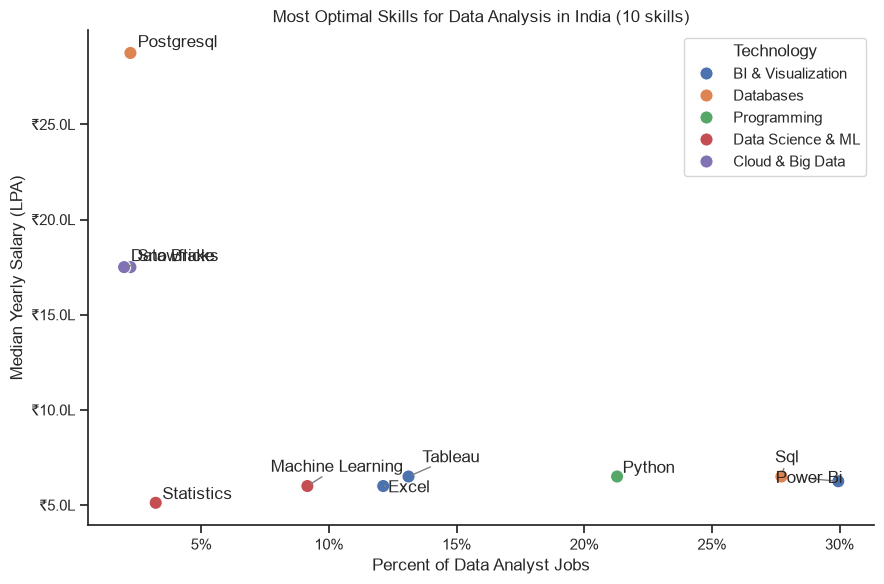

In [61]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

# 1. Parse skills cleanly row-by-row
def parse_skills(val):
    if isinstance(val, list):
        return val
    if isinstance(val, str):
        val = val.strip()
        if val.startswith('[') and val.endswith(']'):
            try:
                return ast.literal_eval(val)
            except (ValueError, SyntaxError):
                pass
        return [s.strip() for s in val.split(',') if s.strip()]
    return []

# 2. Filter for Data Analyst postings
df_da = df[df['job_title'] == 'Data Analyst'].copy()
total_da_jobs = len(df_da)

df_da = df_da[df_da['skills_required'].notna() & (df_da['skills_required'] != 'Not Available')].copy()
df_da['skills_list'] = df_da['skills_required'].apply(parse_skills)

df_da_clean = df_da.explode('skills_list').copy()
df_da_clean['skill'] = df_da_clean['skills_list'].astype(str).str.strip().str.title()

# 3. Compute demand % from all postings, and median salary strictly from disclosed salaries (> 0)
demand_df = df_da_clean.groupby('skill').size().reset_index(name='skill_count')
demand_df['skill_percent'] = (demand_df['skill_count'] / total_da_jobs) * 100

salary_df = (
    df_da_clean[df_da_clean['salary_midpoint_lpa'] > 0]
    .groupby('skill')['salary_midpoint_lpa']
    .median()
    .reset_index(name='median_salary')
)

# 4. Map tools to categories directly (avoids duplicate merge rows)
category_map = {
    'Programming': ['Python', 'R', 'Scala', 'Java', 'Vba', 'Sas'],
    'Databases': ['Sql', 'Postgresql', 'Mysql', 'Oracle', 'Mongodb', 'Sql Server'],
    'BI & Visualization': ['Power Bi', 'Tableau', 'Excel', 'Looker', 'Plotly', 'Matplotlib', 'Seaborn'],
    'Cloud & Big Data': ['Aws', 'Azure', 'Azure Cloud', 'Gcp', 'Snowflake', 'Databricks', 'Data Bricks', 'Pyspark', 'Spark'],
    'Data Science & ML': ['Machine Learning', 'Pandas', 'Numpy', 'Scikit-Learn', 'Nlp', 'Eda', 'Statistics']
}
skill_to_cat = {skill: cat for cat, skills in category_map.items() for skill in skills}

df_plot = demand_df.merge(salary_df, on='skill', how='inner')
df_plot['technology'] = df_plot['skill'].map(skill_to_cat)
df_plot = df_plot.dropna(subset=['technology']).sort_values(by='skill_count', ascending=False).head(10)

# 5. Plot the cleaned scatter chart
sns.set_theme(style='ticks')
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_plot,
    x='skill_percent',
    y='median_salary',
    hue='technology',
    s=90
)
sns.despine()

texts = []
for i in range(len(df_plot)):
    texts.append(
        plt.text(
            df_plot['skill_percent'].iloc[i],
            df_plot['median_salary'].iloc[i],
            df_plot['skill'].iloc[i]
        )
    )

adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary (LPA)')
plt.title(f'Most Optimal Skills for Data Analysis in India ({len(df_plot)} skills)')

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'₹{y:.1f}L'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

plt.legend(title='Technology')
plt.tight_layout()
plt.show()